
<center><b>© 2020. Content is made available under the <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC-BY-NC-ND 4.0</a> license by Christian Lopez, lopezbec@lafayette.edu<b><center>

# Introduction to K-Means Clustering
---



In this notebook you will learn about k-mean clustering algorithm.

<br>
Most of the notebooks we are going to be using are inspired from existing notebooks that are available online and are made free for educational purposes. Nonetheless, these notebooks should not be share without prior permission of the instructor. When working in an assignment always remember the [Student Code of Conduct](https://conduct.lafayette.edu/student-handbook/student-code-of-conduct/).

*The following sections were inspired and uses some of the code and text from the books:

- VanderPlas, J. (2016). Python data science handbook: Essential tools for working with data. O'Reilly Media ( ISBN-10: 9781491912058 ) [Chapter 5](https://colab.research.google.com/github/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.11-K-Means.ipynb)

**Compatibility note (updated November 2026):** This notebook uses the modern `sklearn.datasets.make_blobs` import, explicit `KMeans(n_init=10, random_state=...)` settings, and the current `scipy.stats.mode(..., keepdims=False).mode` result. It is intended to run in a standard Google Colab Python runtime without additional package installation. Run the cells **in order** because later sections reuse variables such as `X`, `K`, and `labels`.

## 1- Introducing k-Means

Clustering algorithms seek to learn, from the properties of the data, an optimal division or discrete labeling of groups of points.

Many clustering algorithms are available in Scikit-Learn and elsewhere, but perhaps the simplest to understand is an algorithm known as *k-means clustering*, which is implemented in ``sklearn.cluster.KMeans``.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn

sns.set_theme()  # Modern seaborn plotting style
print(f"NumPy {np.__version__} | SciPy {scipy.__version__} | scikit-learn {sklearn.__version__}")

NumPy 2.4.6 | SciPy 1.16.3 | scikit-learn 1.6.1


The *k*-means algorithm searches for a specified number of clusters in an unlabeled multidimensional dataset.
It uses the following ideas:

- Each cluster center is the arithmetic mean of the points assigned to that cluster.
- Each data point is assigned to the nearest center using [Euclidean distance](https://en.wikipedia.org/wiki/Euclidean_distance).

We will first create a two-dimensional dataset with **four** groups. Because this is an unsupervised method, we will not use the known group labels to fit the model.

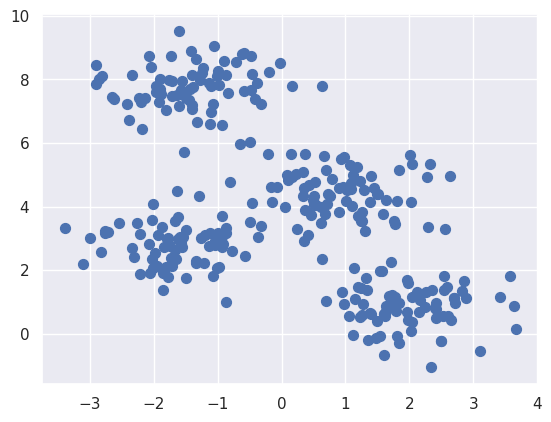

In [2]:
from sklearn.datasets import make_blobs

K = 4
X, y_true = make_blobs(
    n_samples=300, centers=K, cluster_std=0.70, random_state=0
)
plt.scatter(X[:, 0], X[:, 1], s=50)
plt.show()

By eye, it is relatively easy to pick out the four clusters.
The *k*-means algorithm does this automatically, you only need to provide the number of cluster. This can be done with the Scikit-Learn `KMeans`

In [3]:
from sklearn.cluster import KMeans

# Use an explicit number of initializations so results do not depend on
# changes to scikit-learn's default n_init setting.
kmeans = KMeans(n_clusters=K, n_init=10, random_state=0)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)

Let's visualize the results by plotting the data colored by these labels.
We will also plot the cluster centers as determined by the *k*-means estimator:

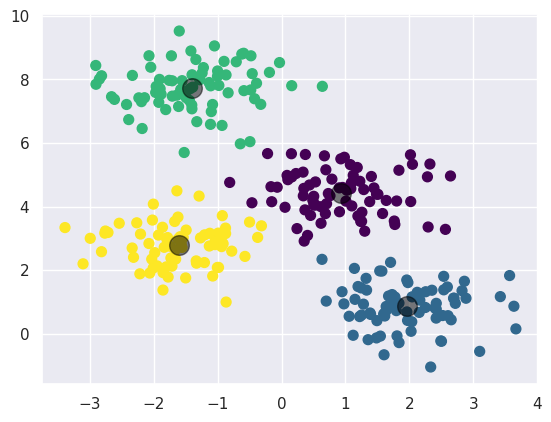

In [4]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='black', s=200, alpha=0.5);

The good news is that the *k*-means algorithm (at least in this simple case) assigns the points to clusters very similarly to how we might assign them by eye.
But you might wonder how this algorithm finds these clusters so quickly! After all, the number of possible combinations of cluster assignments is exponential in the number of data points—an exhaustive search would be very, very costly.
Fortunately for us, such an exhaustive search is not necessary: instead, the typical approach to *k*-means involves an intuitive iterative approach known as *expectation–maximization*.

## 2- Intuition of k-Means Algorithm : Expectation–Maximization

Expectation–maximization (E–M) is a powerful algorithm that comes up in a variety of contexts within data science.
*k*-means is a particularly simple and easy-to-understand application of the algorithm, and we will walk through it briefly here.
In short, the expectation–maximization approach here consists of the following procedure:

1. Guess some cluster centers
2. Repeat until converged
   1. *E-Step*: assign points to the nearest cluster center
   2. *M-Step*: set the cluster centers to the mean

Here the "E-step" or "Expectation step" is so-named because it involves updating our expectation of which cluster each point belongs to.
The "M-step" or "Maximization step" is so-named because it involves maximizing some fitness function that defines the location of the cluster centers—in this case, that maximization is accomplished by taking a simple mean of the data in each cluster.

The literature about this algorithm is vast, but can be summarized as follows: under typical circumstances, each repetition of the E-step and M-step will always result in a better estimate of the cluster characteristics.


The *k*-Means algorithm is simple enough that we can write it in a few lines of code.
The following is a very basic implementation:

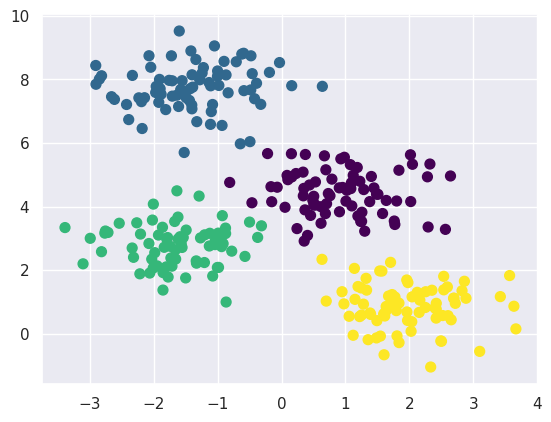

In [5]:
from sklearn.metrics import pairwise_distances_argmin

def find_clusters(X, n_clusters, rseed=2, max_iter=300):
    # 1. Select starting centers from observed data points.
    rng = np.random.RandomState(rseed)
    chosen = rng.permutation(X.shape[0])[:n_clusters]
    centers = X[chosen].copy()

    for _ in range(max_iter):
        # 2a. E-step: assign each point to the nearest center.
        labels = pairwise_distances_argmin(X, centers)

        # 2b. M-step: replace each center with the mean of its assigned points.
        # Retain the previous center if a cluster temporarily becomes empty.
        new_centers = np.array([
            X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
            for j in range(n_clusters)
        ])

        # 2c. Stop when the cluster centers stop changing appreciably.
        if np.allclose(centers, new_centers):
            centers = new_centers
            break
        centers = new_centers

    # Ensure returned labels correspond to the final centers.
    labels = pairwise_distances_argmin(X, centers)
    return centers, labels

centers, labels = find_clusters(X, K)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

Well-tested implementations such as scikit-learn's `KMeans` add optimizations and safeguards, but the preceding function demonstrates the basic assignment/update idea.

The next figure illustrates **three iterations** of this process, beginning with a particular set of random centers. Three iterations do not necessarily mean the algorithm has fully converged.

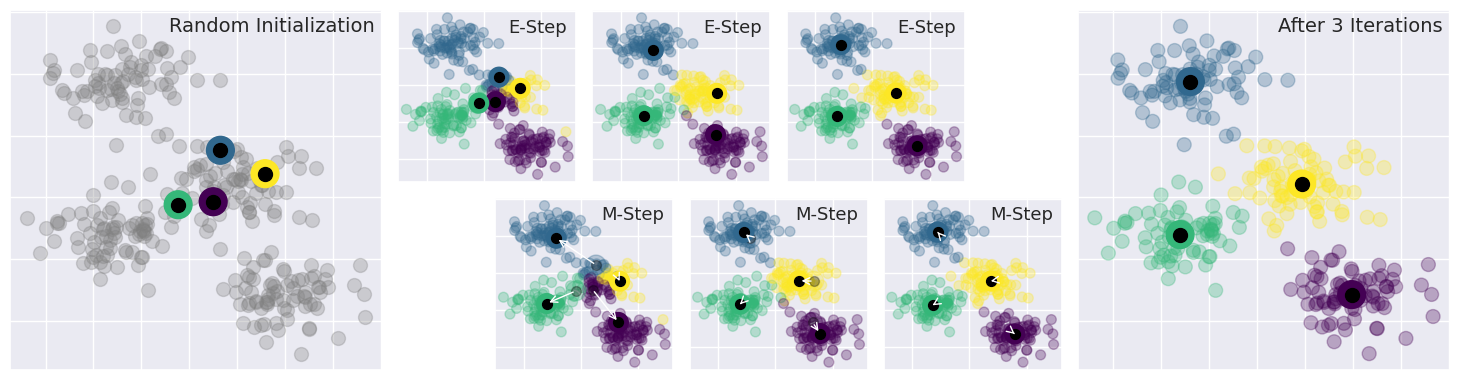

In [6]:
rng = np.random.RandomState(42)
centers = np.array([0, 4]) + rng.randn(K, 2)

def draw_points(ax, colors, factor=1):
    kwargs = {'s': 50 * factor, 'alpha': 0.3}
    if isinstance(colors, str):
        ax.scatter(X[:, 0], X[:, 1], color=colors, **kwargs)
    else:
        ax.scatter(X[:, 0], X[:, 1], c=colors, cmap='viridis', **kwargs)

def draw_centers(ax, centers, factor=1, alpha=1.0):
    ax.scatter(centers[:, 0], centers[:, 1],
               c=np.arange(len(centers)), cmap='viridis',
               s=200 * factor, alpha=alpha)
    ax.scatter(centers[:, 0], centers[:, 1],
               color='black', s=50 * factor, alpha=alpha)

def make_ax(fig, gs):
    ax = fig.add_subplot(gs)
    ax.xaxis.set_major_formatter(plt.NullFormatter())
    ax.yaxis.set_major_formatter(plt.NullFormatter())
    return ax

fig = plt.figure(figsize=(15, 4))
gs = plt.GridSpec(4, 15, left=0.02, right=0.98, bottom=0.05,
                  top=0.95, wspace=0.2, hspace=0.2)
ax0 = make_ax(fig, gs[:4, :4])
ax0.text(0.98, 0.98, 'Random Initialization', transform=ax0.transAxes,
         ha='right', va='top', size=14)
draw_points(ax0, 'gray', factor=2)
draw_centers(ax0, centers, factor=2)

for step in range(3):
    ax1 = make_ax(fig, gs[:2, 4 + 2 * step:6 + 2 * step])
    ax2 = make_ax(fig, gs[2:, 5 + 2 * step:7 + 2 * step])

    # E-step: assign points to the nearest center.
    y_pred = pairwise_distances_argmin(X, centers)
    draw_points(ax1, y_pred)
    draw_centers(ax1, centers)

    # M-step: move each center to the average of its assigned points.
    new_centers = np.array([
        X[y_pred == j].mean(axis=0) if np.any(y_pred == j) else centers[j]
        for j in range(K)
    ])
    draw_points(ax2, y_pred)
    draw_centers(ax2, centers, alpha=0.3)
    draw_centers(ax2, new_centers)
    for cluster_idx in range(K):
        ax2.annotate('', new_centers[cluster_idx], centers[cluster_idx],
                     arrowprops=dict(arrowstyle='->', linewidth=1))

    centers = new_centers
    ax1.text(0.95, 0.95, 'E-Step', transform=ax1.transAxes,
             ha='right', va='top', size=13)
    ax2.text(0.95, 0.95, 'M-Step', transform=ax2.transAxes,
             ha='right', va='top', size=13)

# Show the assignments after the three illustrated iterations.
y_pred = pairwise_distances_argmin(X, centers)
axf = make_ax(fig, gs[:4, -4:])
draw_points(axf, y_pred, factor=2)
draw_centers(axf, centers, factor=2)
axf.text(0.98, 0.98, 'After 3 Iterations', transform=axf.transAxes,
         ha='right', va='top', size=14)
plt.show()

## 3- Caveats of K-means

There are a few issues to be aware of when using the expectation–maximization algorithm.

#### 3.1- The globally optimal result may not be achieved


First, although the E–M procedure is guaranteed to improve the result in each step, there is no assurance that it will lead to the *global* best solution.
For example, if we use a different random seed in a different dataset (k=4) in our simple procedure, the particular starting guesses lead to poor results:

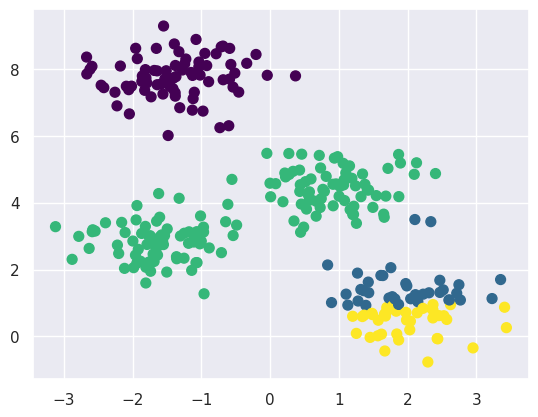

In [7]:
K = 4
X, y_true = make_blobs(
    n_samples=300, centers=K, cluster_std=0.60, random_state=0
)

centers, labels = find_clusters(X, K, rseed=0)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

Here the simple assignment/update procedure has converged to a suboptimal configuration. One common safeguard is to rerun K-means using multiple starting points and keep the result with the lowest inertia (sum of squared distances within clusters).

In current scikit-learn versions, `KMeans` defaults to `n_init='auto'`, which ordinarily performs **one run** with the default `init='k-means++'`. We set `n_init=10` explicitly in the examples to use ten initializations and make this choice clear.

#### 3.2 -The number of clusters must be selected beforehand


Another common challenge with *k*-means is that you must tell it how many clusters you expect: it cannot learn the number of clusters from the data.
For example, if we ask the algorithm to identify six clusters, it will happily proceed and find the best six clusters:

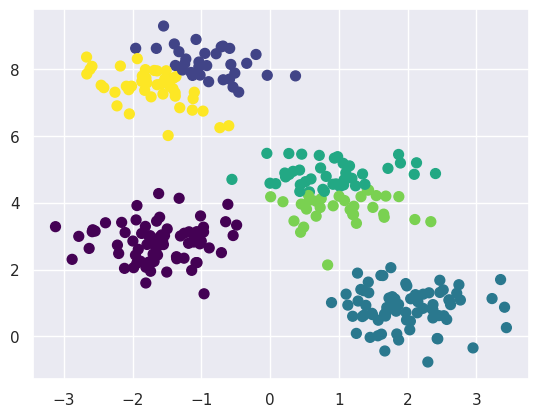

In [8]:
labels = KMeans(n_clusters=6, random_state=0, n_init=10).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

Whether the result is meaningful is a difficult question. One intuitive approach for selecting the number of clusters is [silhouette analysis](https://scikit-learn.org/stable/auto_examples/cluster/plot_kmeans_silhouette_analysis.html).

Other techniques may be better for different cluster shapes and assumptions, including Gaussian mixture models, DBSCAN, mean-shift, and affinity propagation.

#### 3.3- k-means is limited to linear cluster boundaries


The fundamental model assumptions of *k*-means (points will be closer to their own cluster center than to others) means that the algorithm will often be ineffective if the clusters have complicated geometries.

In particular, the boundaries between *k*-means clusters will always be linear, which means that it will fail for more complicated boundaries.
Consider the following data, along with the cluster labels found by the typical *k*-means approach:

In [9]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

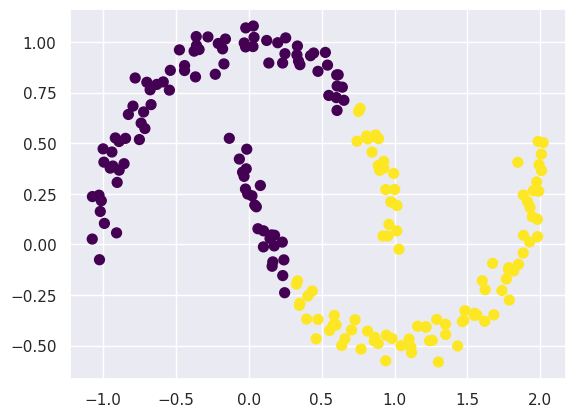

In [10]:
labels = KMeans(n_clusters=2, random_state=0, n_init=10).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

The crescent-shaped groups are not separable by the linear boundaries produced by ordinary K-means. One alternative is **spectral clustering**, which builds a similarity graph, embeds the observations in a different representation, and then can use K-means to assign clusters.

The `SpectralClustering` estimator below uses a 15-nearest-neighbor graph and `assign_labels='kmeans'`. It is related to spectral/kernel methods but is not itself the same algorithm as ordinary K-means.

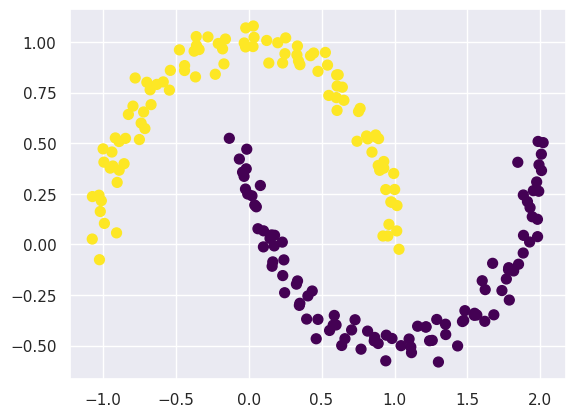

In [11]:
from sklearn.cluster import SpectralClustering

model = SpectralClustering(
    n_clusters=2, affinity='nearest_neighbors', n_neighbors=15,
    assign_labels='kmeans', random_state=0
)
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels, s=50, cmap='viridis')
plt.show()

Spectral clustering can identify the nonlinear crescent-shaped groups much more successfully than ordinary K-means in this example.

#### 3.4- k-means can be slow for large numbers of samples


Because each iteration of *k*-means must access every point in the dataset, the algorithm can be relatively slow as the number of samples grows.
You might wonder if this requirement to use all data at each iteration can be relaxed; for example, you might just use a subset of the data to update the cluster centers at each step.
This is the idea behind batch-based *k*-means algorithms, one form of which is implemented in ``sklearn.cluster.MiniBatchKMeans``.
The interface for this is the same as for standard ``KMeans``; we will see an example of its use as we continue our discussion.

## 4- K-means on the scikit-learn handwritten digits dataset


Being careful about these limitations of the algorithm, we can use *k*-means to our advantage in a wide variety of situations.
We'll now take a look at a couple examples.

We will apply K-means to handwritten digits and try to group similar images **without supplying digit labels to the clustering algorithm**.

We use scikit-learn's built-in **digits** dataset (not the larger MNIST dataset). It contains 1,797 images, each represented by 64 pixel-intensity features from an 8×8 image. The known digit labels are retained so we can evaluate the clusters after fitting.

In [12]:
from sklearn.datasets import load_digits

digits = load_digits()
X = digits.data
y = digits.target
X.shape

(1797, 64)

The clustering can be performed as we did before:

In [13]:
kmeans = KMeans(n_clusters=10, random_state=5, n_init=10)
clusters = kmeans.fit_predict(X)
kmeans.cluster_centers_.shape

(10, 64)

The result is 10 clusters in 64 dimensions.
Notice that the cluster centers themselves are 64-dimensional points, and can themselves be interpreted as the "typical" digit within the cluster.
Let's see what these cluster centers look like:

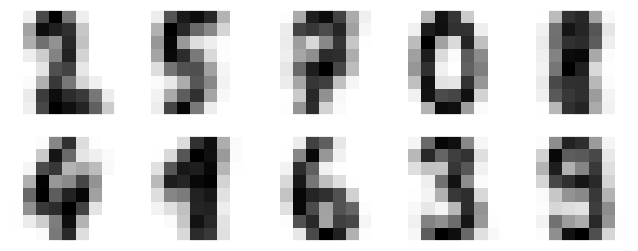

In [14]:
fig, ax = plt.subplots(2, 5, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(10, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)

The centers resemble representative digit images, although some are less clear than others.

K-means cluster IDs are arbitrary (for example, cluster 0 is not automatically the digit 0). To compare clustering results against actual digit labels, we will assign each cluster the **most common true digit label** among its members.

**Important:** This matching step uses the true labels *after* unsupervised clustering. It is an evaluation technique, not an unlabeled way to identify which digit a cluster represents.

In [15]:
from scipy.stats import mode

# Match each cluster to its most frequent true digit label.
# True labels are used only for evaluating the clustering, not to fit KMeans.
labels = np.zeros_like(clusters)
for cluster_idx in range(10):
    mask = (clusters == cluster_idx)
    if np.any(mask):
        labels[mask] = mode(y[mask], keepdims=False).mode

We can now measure the proportion of digits whose true label agrees with the majority-label mapping of their assigned cluster. This is an **in-sample clustering evaluation**, not a measure of predictive accuracy on new images.

In [16]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y, labels)
print(f'K-means label-alignment accuracy on the digits dataset: {accuracy:.1%}')

K-means label-alignment accuracy on the digits dataset: 79.5%


The resulting score depends on initialization, the data representation, and the version of the clustering implementation. Rather than assuming a fixed percentage, refer to the score printed by the cell above. Let's inspect a confusion matrix to see which digits are grouped together.

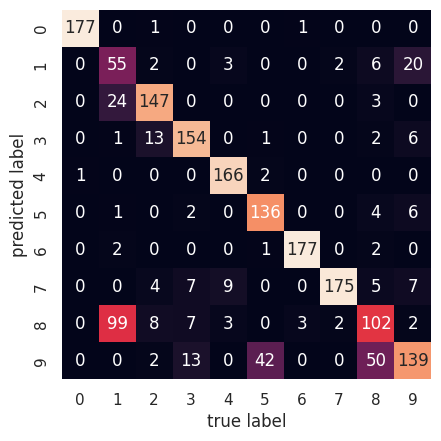

In [17]:
from sklearn.metrics import confusion_matrix
mat = confusion_matrix(digits.target, labels)
sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
            xticklabels=digits.target_names,
            yticklabels=digits.target_names)
plt.xlabel('true label')
plt.ylabel('predicted label');

The confusion matrix highlights which digit labels are often grouped together. Remember that K-means learned the groups without labels, but we **used true labels to name the clusters and calculate this score**; this is not a fully label-free digit classifier.

We can examine these groups by plotting the first 15 example images assigned to each digit label.

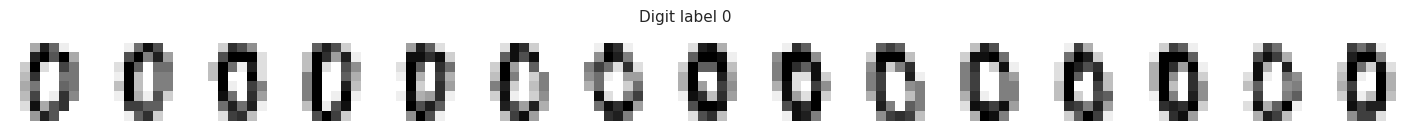

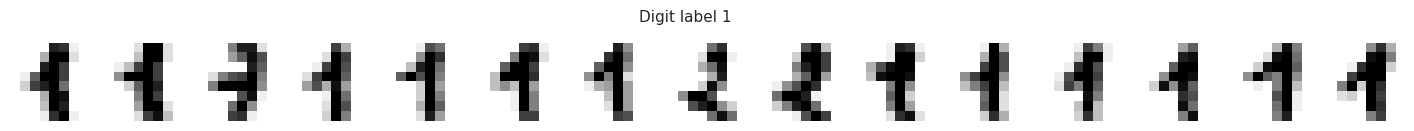

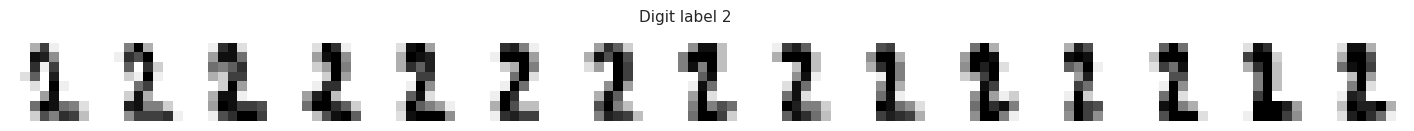

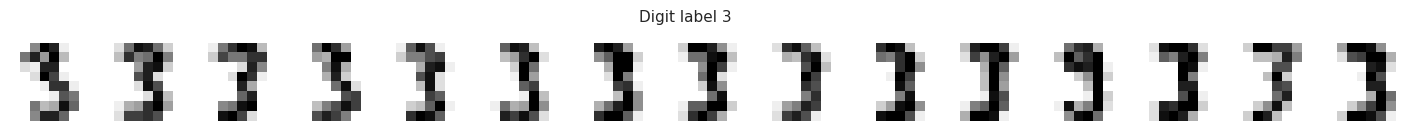

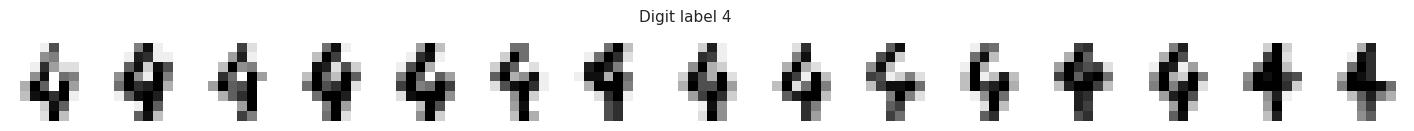

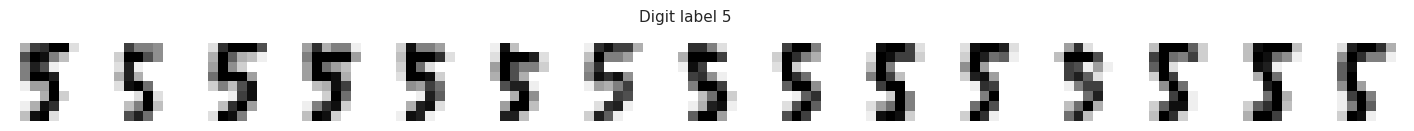

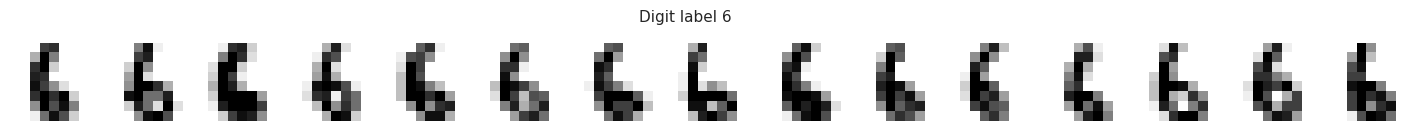

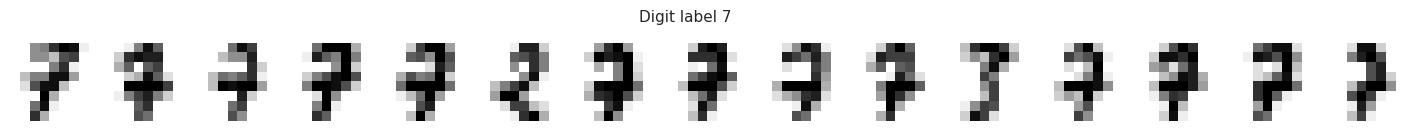

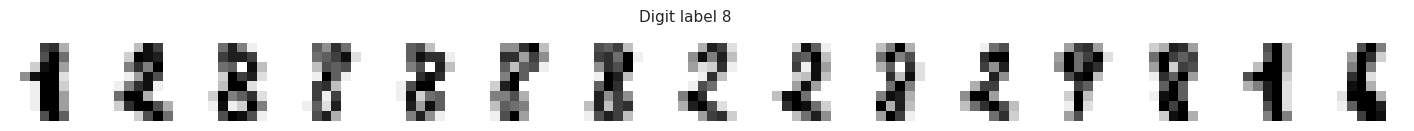

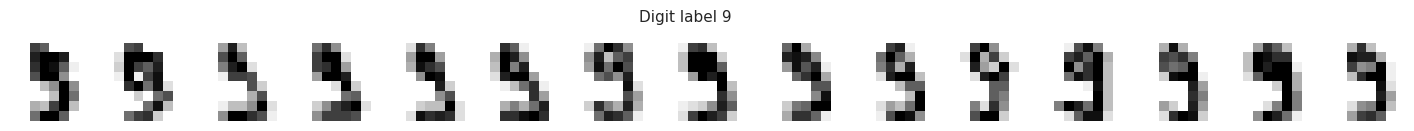

In [18]:
# Display up to 15 example images for each aligned digit label.
for digit_label in range(10):
    selected_indices = np.flatnonzero(labels == digit_label)[:15]
    if len(selected_indices) == 0:
        continue

    fig, axes = plt.subplots(1, len(selected_indices),
                            figsize=(1.2 * len(selected_indices), 1.5))
    for ax, sample_idx in zip(np.atleast_1d(axes), selected_indices):
        ax.imshow(X[sample_idx].reshape(8, 8), cmap='binary',
                  interpolation='nearest')
        ax.axis('off')
    fig.suptitle(f'Digit label {digit_label}', fontsize=11)
    plt.show()

Finally, we can explore whether a nonlinear feature representation changes the clusters. We will use **t-distributed stochastic neighbor embedding (t-SNE)** to project the 64-dimensional digit data into two dimensions before applying K-means.

This is an exploratory illustration: t-SNE emphasizes local structure and is not generally intended to maximize clustering accuracy. The comparison is also evaluated on the same data used to build the embedding; it does not measure performance on unseen samples.

In [19]:
from sklearn.manifold import TSNE

# Project the 64-pixel features into two dimensions (may take a little time).
tsne = TSNE(n_components=2, init='random', learning_rate='auto',
            max_iter=1000, random_state=0)
digits_proj = tsne.fit_transform(X)

# Cluster the two-dimensional representation, without fitting on true labels.
kmeans = KMeans(n_clusters=10, random_state=0, n_init=10)
clusters = kmeans.fit_predict(digits_proj)

# Align cluster IDs to digit labels using the ground truth for evaluation only.
labels = np.zeros_like(clusters)
for cluster_idx in range(10):
    mask = (clusters == cluster_idx)
    if np.any(mask):
        labels[mask] = mode(y[mask], keepdims=False).mode

accuracy_tsne = accuracy_score(y, labels)
print(f't-SNE + K-means label-alignment accuracy: {accuracy_tsne:.1%}')

t-SNE + K-means label-alignment accuracy: 94.1%


Compare the t-SNE + K-means score with the score from K-means on the original 64-dimensional digit features. The values may differ across scikit-learn versions and parameter choices.

Both clustering models fit without digit labels, but the **majority-label mapping and reported accuracy require the true digit labels**. They should be interpreted as descriptive results for this dataset, not as evidence of out-of-sample classification performance.